<b><font size="10" color="#0a65c7"> Notebook 1 - Data Exploration </font></b><br>

This shared notebook is the starting point for the intermediate delivery. It audits the supplied files before the group chooses preprocessing or modelling decisions. Run all cells in JupyterLab from the repository root or the notebooks directory.

**Question:** Can we predict whether a customer will make another purchase within 90 days of the current purchase?



<div class="alert alert-block" style="background-color: #abceff; color: #000000;">

<a id="table-of-contents"></a>

## <font color="#0a65c7">Table of Contents</font>

<h3><a href="#1-import-and-explore-the-data" style="color: #0a65c7; text-decoration: none;">1. Import and Explore the Data</a></h3>

<ul>
  <li style="color: #0a65c7;">
    <a href="#11-imports-and-configuration" style="color: #0a65c7;">1.1 Imports and Configuration</a>
  </li>
  <li style="color: #0a65c7;">
    <a href="#12-data-loading" style="color: #0a65c7;">1.2 Data Loading</a>
  </li>
  <li style="color: #0a65c7;">
    <a href="#13-first-look-at-the-data" style="color: #0a65c7;">1.3 First Look at the Data</a>
  </li>
  <li style="color: #0a65c7;">
    <a href="#14-target-distribution" style="color: #0a65c7;">1.4 Target Distribution</a>
  </li>
  <li style="color: #0a65c7;">
    <a href="#15-structure-and-data-quality" style="color: #0a65c7;">1.5 Structure and Data Quality</a>
    <ul>
      <li style="color: #0a65c7;">
        <a href="#dataset-structure" style="color: #0a65c7;">Dataset Structure</a>
      </li>
      <li style="color: #0a65c7;">
        <a href="#descriptive-statistics" style="color: #0a65c7;">Descriptive Statistics</a>
        <ul>
          <li style="color: #0a65c7;">
            <a href="#numerical-variables" style="color: #0a65c7;">Numerical Variables</a>
          </li>
          <li style="color: #0a65c7;">
            <a href="#categorical-variables" style="color: #0a65c7;">Categorical Variables</a>
            <ul>
              <li style="color: #0a65c7;">
                <a href="#transport-method-frequencies" style="color: #0a65c7;">Transport Method Frequencies</a>
              </li>
            </ul>
          </li>
        </ul>
      </li>
      <li style="color: #0a65c7;">
          <a href="#missing-values" style="color: #0a65c7;">Missing Values</a>
      </li>
      <li style="color: #0a65c7;">
        <a href="#percentage-of-missing-values" style="color: #0a65c7;">Percentage of Missing Values</a>
      </li>
      <li style="color: #0a65c7;">
        <a href="#duplicated-data" style="color: #0a65c7;">Duplicated Data</a>
      </li>
    </ul>
  </li>
  <li style="color: #0a65c7;">
    <a href="#16-initial-feature-roles" style="color: #0a65c7;">1.6 Initial Feature Roles</a>
  </li>
  <li style="color: #0a65c7;">
    <a href="#17-file-structure-checks" style="color: #0a65c7;">1.7 File Structure Checks</a>
  </li>
  <li style="color: #0a65c7;">
    <a href="#18-univariate-analysis" style="color: #0a65c7;">1.8 Univariate Analysis</a>
  </li>
  <li style="color: #0a65c7;">
    <a href="#19-relationships-with-the-target" style="color: #0a65c7;">1.9 Relationships with the Target</a>
    <ul>
      <li style="color: #0a65c7;">
        <a href="#does-missing-historical-information-carry-signal" style="color: #0a65c7;">Does missing historical information carry signal?</a>
      </li>
    </ul>
  </li>
  <li style="color: #0a65c7;">
    <a href="#110-relationships-between-predictors" style="color: #0a65c7;">1.10 Relationships Between Predictors</a>
  </li>
  <li style="color: #0a65c7;">
    <a href="#111-data-consistency-and-proposed-cleaning-rules" style="color: #0a65c7;">1.11 Data Consistency and Proposed Cleaning Rules</a>
  </li>
  <li style="color: #0a65c7;">
    <a href="#112-exploration-summary-and-cleaning-contract" style="color: #0a65c7;">1.12 Exploration Summary and Cleaning Contract</a>
  </li>
</ul>

</div>

<a id="1-import-and-explore-the-data"></a>

## <font color="#0a65c7">1. Import and Explore the Data</font>

<a id="11-imports-and-configuration"></a>

### <font color="#0a65c7">1.1 Imports and Configuration</font>
 
<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid')

RANDOM_STATE = 42
TARGET = 'repeat_purchase_90d'
DATA_DIR = Path('data')
if not DATA_DIR.is_dir():
    DATA_DIR = Path('..') / 'data'
if not DATA_DIR.is_dir():
    raise FileNotFoundError('Open this notebook from the repository root or the notebooks directory.')

<a id="12-data-loading"></a>

### <font color="#0a65c7">1.2 Data Loading</font>

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

In [2]:
train = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')
sample_submission = pd.read_csv(DATA_DIR / 'sample_submission.csv')

print(f'Train: {train.shape[0]:,} rows x {train.shape[1]} columns')
print(f'Test: {test.shape[0]:,} rows x {test.shape[1]} columns')
print(f'Sample submission: {sample_submission.shape[0]:,} rows x {sample_submission.shape[1]} columns')

Train: 6,534 rows x 39 columns
Test: 986 rows x 38 columns
Sample submission: 986 rows x 2 columns


<a id="13-first-look-at-the-data"></a>

### <font color="#0a65c7">1.3 First Look at the Data</font>

Each row of `train` and `test` is a purchase occasion. `train` additionally contains the known binary target. This notebook focuses on the transaction data; the optional `clientes.csv` table is explored separately in Notebook 02.

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

In [3]:
print('TRAIN:')
display(train.head())
print()

print('TEST:')
display(test.head())
print()

print('SAMPLE SUBMISSION:')
display(sample_submission.head())

TRAIN:


,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,repeat_purchase_90d,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,1,79.0,126.0,2.0,858.30,429.150000,112.656252,349.49,508.81,47.000000,NaN,0.0,0.00,1.0,349.49,2.0,858.30,2.0,858.30,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,10000000,-0.660448
1,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,1,244.0,616.0,5.0,6722.83,1344.566000,1683.795178,84.38,4222.15,93.000000,117.657696,0.0,0.00,0.0,0.00,0.0,0.00,4.0,2500.68,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,10000001,0.924510
2,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,1,9.0,610.0,90.0,17590.08,195.445333,190.389932,4.54,1002.15,6.752809,6.384073,2.0,111.27,9.0,1928.55,28.0,5290.25,49.0,7899.80,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,10000002,-0.258730
3,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,0,97.0,97.0,1.0,270.33,270.330000,NaN,270.33,270.33,NaN,NaN,0.0,0.00,0.0,0.00,1.0,270.33,1.0,270.33,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,10000003,1.448402
4,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,1,85.0,1575.0,25.0,12803.02,512.120800,406.696963,22.58,1736.74,62.083333,66.246520,0.0,0.00,2.0,184.13,4.0,2062.50,4.0,2062.50,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,10000004,-1.058890



TEST:


,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,286.37,582.05,232.82,53.55,0.0,0.0,349.23,104.409267,22,1,40.0,3905,122,46287.23,379.403525,528.297548,2.72,3198.00,31.942149,48.035282,0,0.0,6,1295.82,9,2498.90,23,9140.12,519184,Maybe Tomorrow Payment 12,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 80,Final Excel Warehouse 1,Ctrl Z Series 2,2026-08-22,10000006,0.621602
1,1949.25,1725.00,1725.00,224.25,0.0,0.0,0.00,0.000000,1,1,63.0,3613,58,243340.48,4195.525517,2545.945318,569.52,11031.74,62.280702,46.416113,0,0.0,1,3137.11,2,5086.36,4,16252.35,942149,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 2,2025-07-26,10000008,-1.318874
2,2738.71,4114.83,2738.71,0.00,0.0,0.0,1376.12,1019.466586,99,1,230.0,1786,16,21570.23,1348.139375,1096.651106,40.09,3363.23,103.733333,78.583410,0,0.0,0,0.00,0,0.00,4,4570.76,386654,Maybe Tomorrow Payment 4,VLOOKUP Master 1,Decorative Dashboard Zone 2,Maybe Tomorrow Delivery 54,Final Excel Warehouse 1,Ctrl Z Series 2,2026-08-22,10000010,1.251905
3,726.98,591.04,591.04,135.94,0.0,0.0,0.00,341.649008,39,2,234.0,374,3,3907.61,1302.536667,881.237007,296.37,1937.15,70.000000,67.882251,0,0.0,0,0.00,0,0.00,2,1970.46,588088,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 35,Final Excel Warehouse 1,Ctrl Z Series 2,2025-11-05,10000020,0.988362
4,670.76,555.49,545.33,125.43,0.0,0.0,10.16,326.715748,13,1,NaN,386,5,4877.08,975.416000,334.407265,546.28,1305.09,77.000000,43.825411,0,0.0,1,759.06,2,2062.37,4,4330.80,610152,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 1,Maybe Tomorrow Delivery 73,Final Excel Warehouse 1,Ctrl Z Series 2,2026-07-12,10000025,0.511535



SAMPLE SUBMISSION:


,ID,repeat_purchase_90d
0,10000006,1
1,10000008,1
2,10000010,1
3,10000020,0
4,10000025,1


<a id="14-target-distribution"></a>

### <font color="#0a65c7">1.4 Target Distribution</font>

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

Target counts:


,count
repeat_purchase_90d,
1,3654
0,2880


Target proportions:


,proportion
repeat_purchase_90d,
1,0.559229
0,0.440771


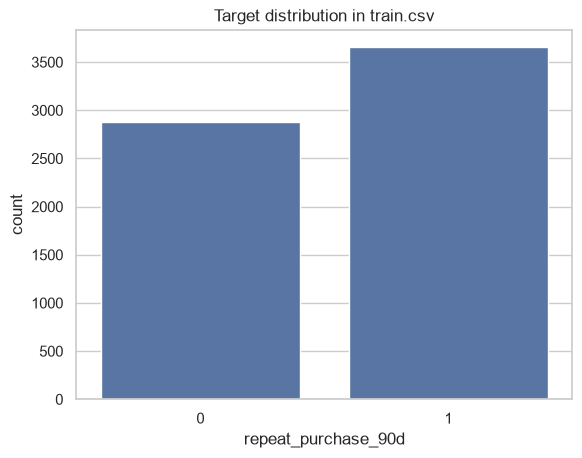

In [4]:
print('Target counts:')
display(train[TARGET].value_counts().rename_axis(TARGET).to_frame('count'))

print('Target proportions:')
display(train[TARGET].value_counts(normalize=True).rename_axis(TARGET).to_frame('proportion'))

ax = sns.countplot(data=train, x=TARGET)
ax.set_title('Target distribution in train.csv')
plt.show()

**Conclusion:** The target classes are reasonably balanced: 55.9% of the observations are class 1 (repeat purchase within 90 days) and 44.1% are class 0 (no repeat purchase within 90 days).

<a id="15-structure-and-data-quality"></a>

### <font color="#0a65c7">1.5 Structure and Data Quality</font>

In this section, we inspect the structure of the training dataset, descriptive statistics, missing values, and duplicated data. At this stage, we only inspect the data and do not make any changes.

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

<a id="dataset-structure"></a>

#### <font color="#0a65c7">Dataset Structure</font>

Show the number of rows, the columns, the number of non-missing values, and the data type of each column. 

In [5]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 6534 entries, 0 to 6533
Data columns (total 39 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Total a Pagar                   6469 non-null   float64
 1   Total Bruto                     6469 non-null   float64
 2   Total Liquido                   6469 non-null   float64
 3   Total Imp_                      6469 non-null   float64
 4   Total Portes                    6469 non-null   float64
 5   Total Desc_ Global              6469 non-null   float64
 6   Total Desc_ Linha               6469 non-null   float64
 7   Custo                           6469 non-null   float64
 8   N_ Detalhes                     6469 non-null   float64
 9   invoice_count_current_purchase  6469 non-null   float64
 10  repeat_purchase_90d             6534 non-null   int64  
 11  days_since_previous_purchase    5673 non-null   float64
 12  customer_tenure_days            6469 non-null

The training dataset contains 6,534 observations, as shown by the `RangeIndex` in `train.info()`. A column has missing values whenever its `Non-Null Count` is below 6,534. All columns have missing values except `repeat_purchase_90d`, `customer_id`, and `ID`, which are complete.

Most incomplete columns have 65 missing values. However, some historical variables have considerably more missing values, particularly `prior_std_gap_days`, `prior_mean_gap_days`, and `prior_std_purchase_value`.

<a id="descriptive-statistics"></a>

#### <font color="#0a65c7">Descriptive Statistics</font>

We summarize the numerical and categorical variables to identify their typical values, distributions, unusual observations, and category frequencies.

<a id="numerical-variables"></a>

##### <font color="#0a65c7">Numerical Variables</font>

We summarize the numerical variables to examine their typical values, distribution, and possible anomalies.

In [6]:
numerical_statistics = train.describe(include='number').T
numerical_statistics

,count,mean,std,min,25%,50%,75%,max
Total a Pagar,6469.0,9.255563e+02,1.334998e+03,9.300000e-01,1.889200e+02,4.767400e+02,1.087670e+03,2.229721e+04
Total Bruto,6469.0,8.861527e+02,1.327641e+03,8.300000e-01,1.757400e+02,4.457400e+02,1.036700e+03,2.157828e+04
Total Liquido,6469.0,7.733364e+02,1.136356e+03,7.600000e-01,1.543800e+02,3.899100e+02,9.033700e+02,1.812781e+04
Total Imp_,6469.0,1.522199e+02,2.252624e+02,0.000000e+00,2.993000e+01,7.974000e+01,1.848400e+02,4.169400e+03
Total Portes,6469.0,1.151427e+00,5.844091e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.810600e+02
Total Desc_ Global,6469.0,3.499072e-01,5.116564e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.184900e+02
Total Desc_ Linha,6469.0,1.124664e+02,2.899863e+02,0.000000e+00,0.000000e+00,1.313000e+01,9.228000e+01,4.103440e+03
Custo,6469.0,3.281650e+02,5.195072e+02,0.000000e+00,4.905000e+01,1.525400e+02,3.960615e+02,7.427401e+03
N_ Detalhes,6469.0,2.152450e+01,2.771342e+01,1.000000e+00,4.000000e+00,1.100000e+01,2.900000e+01,4.230000e+02
invoice_count_current_purchase,6469.0,1.066007e+00,3.108069e-01,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,5.000000e+00


**Conclusion:**

The minimum values of `days_since_previous_purchase` and `prior_mean_gap_days` are negative, which appears implausible for time intervals. `prior_mean_purchase_value` and `spend_365d` also contain negative values and reach a maximum of 1,000,000,000. These values require further investigation.

Several monetary variables have means higher than their medians and maximum values far above their third quartiles, suggesting unusually large observations. At least 75% of purchases have no shipping costs or global discount, and most purchase occasions contain only one invoice.

Although `ID` and `customer_id` appear in this numerical table, they are identifiers, so their means and other numerical statistics have no useful interpretation.

<a id="categorical-variables"></a>

##### <font color="#0a65c7">Categorical Variables</font>

We examine how many different values each text variable has (`unique`), which value is most common (`top`), and how often it appears (`freq`).

In [7]:
categorical_statistics = train.select_dtypes(include=['object', 'category']).describe().T
categorical_statistics

C:\Users\ffbal\AppData\Local\Temp\ipykernel_43084\730899762.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_statistics = train.select_dtypes(include=['object', 'category']).describe().T


,count,unique,top,freq
payment_type,6274,9,Maybe Tomorrow Payment 7,4565
salesperson,6275,9,VLOOKUP Master 1,4054
commercial_zone,6469,5,Decorative Dashboard Zone 4,6260
transport_method,6273,80,Maybe Tomorrow Delivery 72,1119
warehouse,6274,2,Final Excel Warehouse 1,6253
document_series,6469,3,Ctrl Z Series 2,2738
purchase_date,6469,1492,2015-10-31,52


`commercial_zone` and `warehouse` are dominated by one category, while `transport_method` has 80 different categories. We should inspect the frequency of each category before deciding how to use these variables in a model.

`purchase_date` appears in this table because it is currently stored as text. We will need to convert it to a date before analysing time-related patterns.

<a id="transport-method-frequencies"></a>

##### <font color="#0a65c7">Transport Method Frequencies</font>

We count how often each `transport_method` category appears to check whether some categories are rare.

In [8]:
transport_counts = train['transport_method'].value_counts()
transport_counts.tail(20)

transport_method
Maybe Tomorrow Delivery 3     1
Maybe Tomorrow Delivery 16    1
Maybe Tomorrow Delivery 83    1
Maybe Tomorrow Delivery 8     1
Maybe Tomorrow Delivery 30    1
Maybe Tomorrow Delivery 20    1
Maybe Tomorrow Delivery 14    1
Maybe Tomorrow Delivery 29    1
Maybe Tomorrow Delivery 12    1
Maybe Tomorrow Delivery 4     1
Maybe Tomorrow Delivery 67    1
Maybe Tomorrow Delivery 6     1
Maybe Tomorrow Delivery 79    1
Maybe Tomorrow Delivery 52    1
Maybe Tomorrow Delivery 60    1
Maybe Tomorrow Delivery 55    1
Maybe Tomorrow Delivery 58    1
Maybe Tomorrow Delivery 28    1
Maybe Tomorrow Delivery 21    1
Maybe Tomorrow Delivery 23    1
Name: count, dtype: int64

**Conclusion:** The 20 least frequent `transport_method` categories each appear only once in the training data. This confirms that the variable contains rare categories. We will consider this when preparing the data for modelling.

<a id="missing-values"></a>

#### <font color="#0a65c7">Missing Values</font>

We count the number of missing values in each column. This allows us to identify which variables are incomplete and how many observations are missing.

In [9]:
missing_values = train.isna().sum()
missing_values

Total a Pagar                       65
Total Bruto                         65
Total Liquido                       65
Total Imp_                          65
Total Portes                        65
Total Desc_ Global                  65
Total Desc_ Linha                   65
Custo                               65
N_ Detalhes                         65
invoice_count_current_purchase      65
repeat_purchase_90d                  0
days_since_previous_purchase       861
customer_tenure_days                65
prior_purchase_count                65
prior_total_spend                   65
prior_mean_purchase_value          862
prior_std_purchase_value          1113
prior_min_purchase_value           668
prior_max_purchase_value           668
prior_mean_gap_days               1308
prior_std_gap_days                1478
purchase_count_30d                  65
spend_30d                           65
purchase_count_90d                  65
spend_90d                           65
purchase_count_180d      

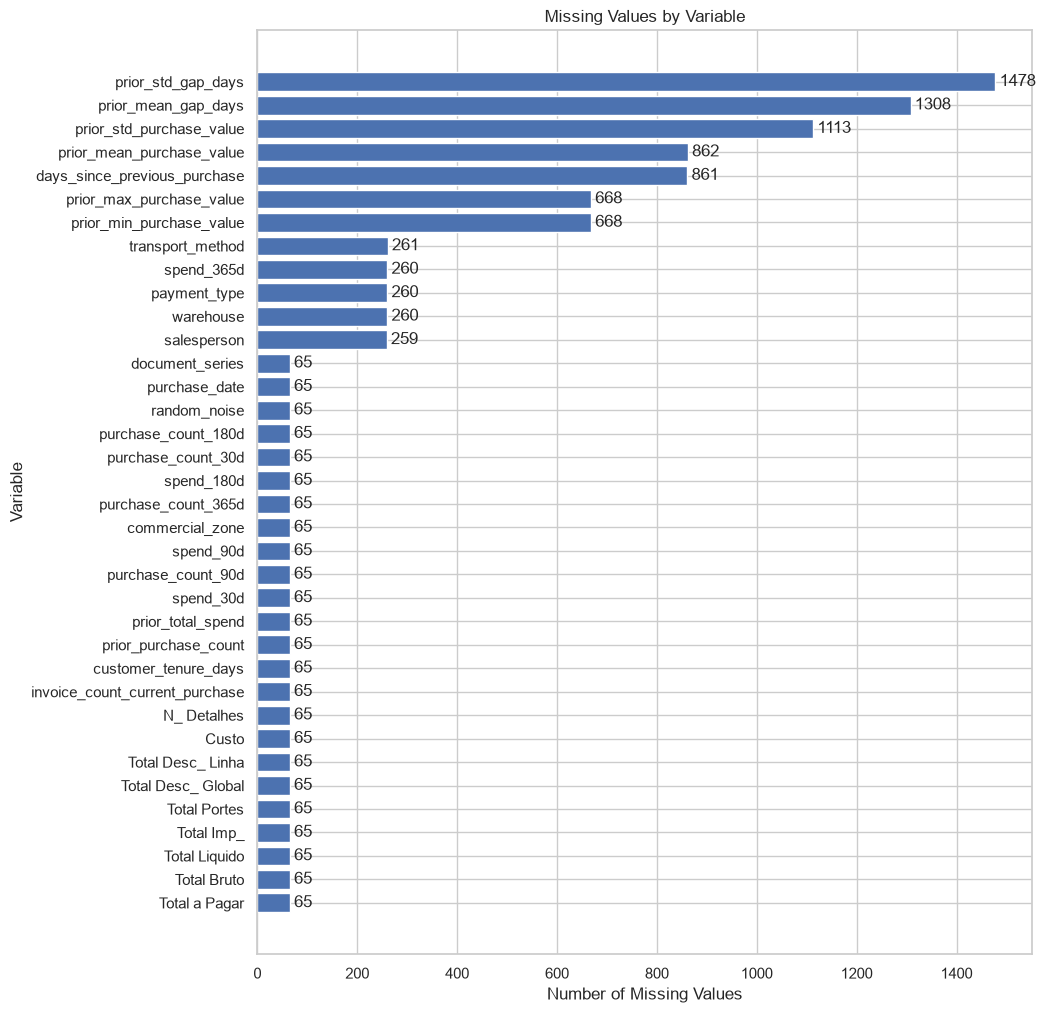

In [10]:
missing_variables = missing_values[missing_values > 0]
missing_variables = missing_variables.sort_values()

plt.figure(figsize=(10, 12))

bars = plt.barh(
    missing_variables.index,
    missing_variables.values
)

plt.bar_label(bars, padding=3)

plt.title('Missing Values by Variable')
plt.xlabel('Number of Missing Values')
plt.ylabel('Variable')

plt.show()

The chart shows that missing values are particularly frequent in variables related to the customers' previous purchasing history. `prior_std_gap_days` has the highest number of missing values, followed by `prior_mean_gap_days` and `prior_std_purchase_value`.

Several other variables have only 65 missing values, suggesting that the same observations may be incomplete across multiple variables. This possibility should be investigated before deciding how to handle the missing data.

<a id="percentage-of-missing-values"></a>

#### <font color="#0a65c7">Percentage of Missing Values</font>

We calculate the percentage of missing values in each incomplete variable. Percentages make it easier to understand the importance of the missing data relative to the total number of observations.

In [11]:
missing_percentage = missing_variables / len(train) * 100
missing_percentage

Total a Pagar                      0.994796
Total Bruto                        0.994796
Total Liquido                      0.994796
Total Imp_                         0.994796
Total Portes                       0.994796
Total Desc_ Global                 0.994796
Total Desc_ Linha                  0.994796
Custo                              0.994796
N_ Detalhes                        0.994796
invoice_count_current_purchase     0.994796
customer_tenure_days               0.994796
prior_purchase_count               0.994796
prior_total_spend                  0.994796
spend_30d                          0.994796
purchase_count_90d                 0.994796
spend_90d                          0.994796
commercial_zone                    0.994796
purchase_count_365d                0.994796
spend_180d                         0.994796
purchase_count_30d                 0.994796
purchase_count_180d                0.994796
random_noise                       0.994796
purchase_date                   

`prior_std_gap_days` has the highest percentage of missing values, with approximately 22.6%, followed by `prior_mean_gap_days` with approximately 20.0% and `prior_std_purchase_value` with approximately 17.0%.

The variables with 65 missing observations have approximately 1.0% missing data.

<a id="duplicated-data"></a>

#### <font color="#0a65c7">Duplicated Data</font>

We check whether the training dataset contains completely duplicated rows. We also repeat the check without `ID`, because a unique row identifier would otherwise hide rows with the same available purchase information.

In [12]:
duplicated_with_id = train.duplicated().sum()

train_without_id = train.drop(columns=['ID'])
duplicated_without_id = train_without_id.duplicated().sum()

print('Duplicated rows including ID:', duplicated_with_id)
print('Duplicated rows excluding ID:', duplicated_without_id)

Duplicated rows including ID: 0
Duplicated rows excluding ID: 10


In [13]:
repeated_rows = train_without_id.duplicated(keep=False)
train[repeated_rows][['ID', 'customer_id', 'purchase_date', TARGET]]

,ID,customer_id,purchase_date,repeat_purchase_90d
393,10000457,755628,NaN,1
484,10000560,755628,NaN,1
839,10000983,334782,NaN,1
2036,10002381,258332,NaN,1
2733,10003209,755628,NaN,1
3178,10003718,334782,NaN,1
3573,10004187,239651,NaN,1
3804,10004463,755628,NaN,1
3956,10004649,928824,NaN,0
4378,10005141,239651,NaN,1


When `ID` is included, no rows are identical. Excluding `ID`, 10 additional rows repeat the available values of earlier rows. The 16 observations involved have many missing values, so we cannot conclude that they are erroneous duplicate purchases. No rows are removed at this stage.

<a id="16-initial-feature-roles"></a>

### <font color="#0a65c7">1.6 Initial Feature Roles</font>

`ID` is the row identifier for Kaggle and must not be used as a predictor. `customer_id` is a join key and potentially identifier-like, so it requires an explicit experiment and justification before use. `purchase_date` must be converted to a date before making any time-based features or validation split.

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

In [14]:
id_columns = ['ID', 'customer_id']
date_columns = ['purchase_date']

numeric_columns = train.select_dtypes(include='number').columns.drop([TARGET, 'ID', 'customer_id']).tolist()
categorical_columns = [
    column for column in train.select_dtypes(include=['object', 'category']).columns
    if column not in id_columns + date_columns
]

print('Numeric predictors:', numeric_columns)
print('Categorical predictors:', categorical_columns)
print('Potential identifier/date columns:', id_columns + date_columns)

dates = pd.to_datetime(train['purchase_date'], errors='coerce')
print(f'Purchase-date range: {dates.min().date()} to {dates.max().date()}')
print(f'Invalid or missing purchase dates: {dates.isna().sum()}')

Numeric predictors: ['Total a Pagar', 'Total Bruto', 'Total Liquido', 'Total Imp_', 'Total Portes', 'Total Desc_ Global', 'Total Desc_ Linha', 'Custo', 'N_ Detalhes', 'invoice_count_current_purchase', 'days_since_previous_purchase', 'customer_tenure_days', 'prior_purchase_count', 'prior_total_spend', 'prior_mean_purchase_value', 'prior_std_purchase_value', 'prior_min_purchase_value', 'prior_max_purchase_value', 'prior_mean_gap_days', 'prior_std_gap_days', 'purchase_count_30d', 'spend_30d', 'purchase_count_90d', 'spend_90d', 'purchase_count_180d', 'spend_180d', 'purchase_count_365d', 'spend_365d', 'random_noise']
Categorical predictors: ['payment_type', 'salesperson', 'commercial_zone', 'transport_method', 'warehouse', 'document_series']
Potential identifier/date columns: ['ID', 'customer_id', 'purchase_date']
Purchase-date range: 2015-07-11 to 2025-02-15
Invalid or missing purchase dates: 65


C:\Users\ffbal\AppData\Local\Temp\ipykernel_43084\1766596447.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  column for column in train.select_dtypes(include=['object', 'category']).columns


<a id="17-file-structure-checks"></a>

### <font color="#0a65c7">1.7 File Structure Checks</font>

We check whether `train` and `test` have the same predictor columns and whether the sample submission has the required columns and IDs.

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

In [15]:
train_predictors = train.drop(columns=[TARGET])

print('Same predictors in the same order:', train_predictors.columns.equals(test.columns))
print('Target in train:', TARGET in train.columns)
print('Target in test:', TARGET in test.columns)
print('Submission columns:', sample_submission.columns.tolist())
print('Submission IDs match test IDs in order:', sample_submission['ID'].equals(test['ID']))

Same predictors in the same order: True
Target in train: True
Target in test: False
Submission columns: ['ID', 'repeat_purchase_90d']
Submission IDs match test IDs in order: True


**Conclusion:** `train` and `test` have the same predictor columns in the same order. Only `train` contains the target. The sample submission has the required `ID` and `repeat_purchase_90d` columns, and its IDs match the `test` IDs in order.

<a id="18-univariate-analysis"></a>

### <font color="#0a65c7">1.8 Univariate Analysis</font>

We inspect a small set of representative numerical variables. The objective is to understand their scale and shape, not to remove observations automatically. The selected variables cover the value of the current purchase, the amount of prior activity, recency and customer tenure.

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

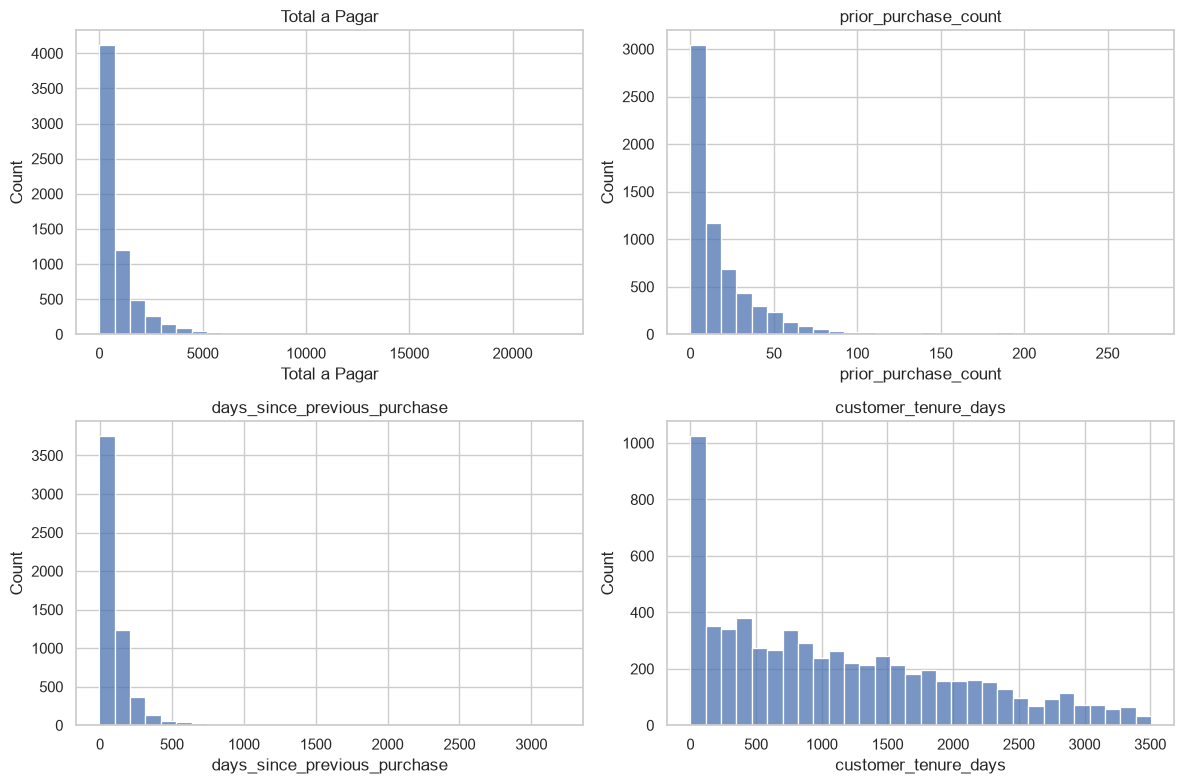

In [16]:
representative_numeric = [
    'Total a Pagar',
    'prior_purchase_count',
    'days_since_previous_purchase',
    'customer_tenure_days',
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for column, axis in zip(representative_numeric, axes.ravel()):
    sns.histplot(data=train, x=column, bins=30, ax=axis)
    axis.set_title(column)

plt.tight_layout()
plt.show()

**Interpretation.** Purchase values and historical activity are right-skewed: most purchases and customers are relatively small, while a few are much larger. A large value is not automatically a mistake in a wholesale setting, so we will not remove observations solely because they are outliers. The exceptional values identified in the data-consistency section are treated differently because they conflict with the meaning of their own variables.

<a id="19-relationships-with-the-target"></a>

### <font color="#0a65c7">1.9 Relationships with the Target</font>

Before fitting a model, we inspect a few transparent relationships with `repeat_purchase_90d`. These summaries are descriptive only; they do not select features or tune a model.

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

In [17]:
target_numeric_summary = (
    train.groupby(TARGET)[representative_numeric]
    .median()
    .T
    .rename(columns={0: 'median_target_0', 1: 'median_target_1'})
)

display(target_numeric_summary)

payment_repeat_rate = (
    train.groupby('payment_type', dropna=False)[TARGET]
    .agg(['count', 'mean'])
    .rename(columns={'mean': 'repeat_purchase_rate'})
    .sort_values('repeat_purchase_rate', ascending=False)
)

display(payment_repeat_rate)

repeat_purchase_90d,median_target_0,median_target_1
Total a Pagar,443.12,517.46
prior_purchase_count,6.00,17.00
days_since_previous_purchase,105.00,37.00
customer_tenure_days,781.00,1032.00


,count,repeat_purchase_rate
payment_type,,
Maybe Tomorrow Payment 9,502,0.950199
Maybe Tomorrow Payment 11,8,0.625000
NaN,260,0.550000
Maybe Tomorrow Payment 12,991,0.542886
Maybe Tomorrow Payment 7,4565,0.527273
Maybe Tomorrow Payment 2,21,0.523810
Maybe Tomorrow Payment 3,4,0.500000
Maybe Tomorrow Payment 4,9,0.444444
Maybe Tomorrow Payment 10,134,0.402985


The target rate differs across purchase history and across some payment categories, so both numerical history and categorical purchase information are reasonable candidates for the first model. This does not establish a causal relationship and does not guarantee that a feature will improve validation performance.

<a id="does-missing-historical-information-carry-signal"></a>

#### <font color="#0a65c7">Does missing historical information carry signal?</font>

Missingness may mean that the customer has too little purchase history for a historical statistic to be calculated. We compare the target rate when selected historical columns are observed versus missing before deciding whether to discard them.

In [18]:
historical_columns = [
    'days_since_previous_purchase',
    'prior_mean_purchase_value',
    'prior_std_purchase_value',
    'prior_mean_gap_days',
    'prior_std_gap_days',
]

missingness_target_summary = pd.DataFrame(
    {
        'column': column,
        'missing_rows': train[column].isna().sum(),
        'repeat_rate_when_observed': train.loc[train[column].notna(), TARGET].mean(),
        'repeat_rate_when_missing': train.loc[train[column].isna(), TARGET].mean(),
    }
    for column in historical_columns
)

display(missingness_target_summary.style.format({
    'repeat_rate_when_observed': '{:.1%}',
    'repeat_rate_when_missing': '{:.1%}',
}))

,column,missing_rows,repeat_rate_when_observed,repeat_rate_when_missing
0,days_since_previous_purchase,861,58.3%,40.0%
1,prior_mean_purchase_value,862,58.3%,40.3%
2,prior_std_purchase_value,1113,60.0%,35.9%
3,prior_mean_gap_days,1308,59.8%,40.4%
4,prior_std_gap_days,1478,61.5%,36.9%


**Decision supported by the data.** Missing historical values are associated with different repeat-purchase rates. In particular, `prior_std_gap_days` is missing for 22.6% of rows and its missing rows have a substantially lower repeat-purchase rate. We will retain these historical columns. In the modelling notebook, numerical missing values will be imputed from the training fold and a missing-value indicator will be retained.

<a id="110-relationships-between-predictors"></a>

### <font color="#0a65c7">1.10 Relationships Between Predictors</font>

Several monetary totals describe the same purchase. We inspect their correlations to record this redundancy before modelling.

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

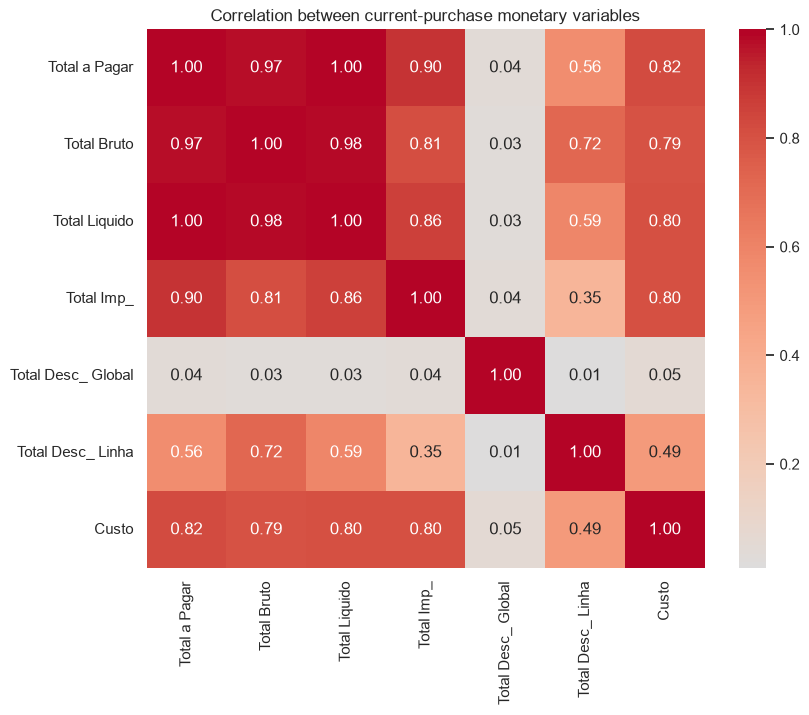

In [19]:
monetary_columns = [
    'Total a Pagar',
    'Total Bruto',
    'Total Liquido',
    'Total Imp_',
    'Total Desc_ Global',
    'Total Desc_ Linha',
    'Custo',
]

plt.figure(figsize=(9, 7))
sns.heatmap(train[monetary_columns].corr(), cmap='coolwarm', center=0, annot=True, fmt='.2f')
plt.title('Correlation between current-purchase monetary variables')
plt.show()

The monetary variables are related, as expected: they are different descriptions of the same purchase. We keep them in the first logistic-regression baseline because scaling and regularisation can handle correlated variables. A later feature-selection experiment can test whether a smaller set performs equally well.

<a id="111-data-consistency-and-proposed-cleaning-rules"></a>

### <font color="#0a65c7">1.11 Data Consistency and Proposed Cleaning Rules</font>

The raw CSV files are never changed. This section identifies records that require a deterministic correction later and distinguishes them from ordinary missing values.

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

In [20]:
model_candidate_columns = [
    column for column in train.columns
    if column not in [TARGET, 'ID', 'customer_id']
]

almost_empty_rows = train[model_candidate_columns].isna().all(axis=1)

print('Rows with every model-candidate value missing:', almost_empty_rows.sum())
display(train.loc[almost_empty_rows, ['ID', 'customer_id', 'purchase_date', TARGET]].head())

quality_checks = pd.DataFrame(
    [
        {
            'column': 'days_since_previous_purchase',
            'issue': 'negative value',
            'affected_rows': (train['days_since_previous_purchase'] < 0).sum(),
        },
        {
            'column': 'prior_mean_purchase_value',
            'issue': 'negative value or 1,000,000,000 sentinel',
            'affected_rows': (
                (train['prior_mean_purchase_value'] < 0)
                | (train['prior_mean_purchase_value'] == 1_000_000_000)
            ).sum(),
        },
        {
            'column': 'prior_mean_gap_days',
            'issue': 'negative value',
            'affected_rows': (train['prior_mean_gap_days'] < 0).sum(),
        },
        {
            'column': 'spend_365d',
            'issue': 'negative value or 1,000,000,000 sentinel',
            'affected_rows': (
                (train['spend_365d'] < 0)
                | (train['spend_365d'] == 1_000_000_000)
            ).sum(),
        },
    ]
)

display(quality_checks)

Rows with every model-candidate value missing: 65


,ID,customer_id,purchase_date,repeat_purchase_90d
393,10000457,755628,NaN,1
484,10000560,755628,NaN,1
582,10000678,427118,NaN,1
583,10000679,508217,NaN,0
748,10000870,427118,NaN,0


,column,issue,affected_rows
0,days_since_previous_purchase,negative value,16
1,prior_mean_purchase_value,"negative value or 1,000,000,000 sentinel",32
2,prior_mean_gap_days,negative value,16
3,spend_365d,"negative value or 1,000,000,000 sentinel",30


Negative time intervals are inconsistent with these historical features. For historical spending and purchase values, we treat negative entries as invalid for these experiments. This is an assumption that should be revisited if returns or credit notes explain them. The exact value `1,000,000,000` is treated as suspected corruption because it is implausible compared with the other historical values. These entries will be converted to missing values (`NaN`) in the modelling notebook. The rows will be retained because their other purchase information remains usable.

The 65 almost-empty rows lack transaction predictors and a purchase date. We will exclude the same rows from both temporal experiments to compare the two feature sets on identical purchases. They could receive customer information after the merge, so this is an experimental choice rather than proof that predictions are impossible. The original CSV remains unchanged.

<a id="112-exploration-summary-and-cleaning-contract"></a>

### <font color="#0a65c7">1.12 Exploration Summary and Cleaning Contract</font>

The following table records the rules to apply in the modelling notebook. Both experiments, transactions only and transactions plus client attributes, will use the same temporal split and the same transaction cleaning rules.

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

In [21]:
cleaning_contract = pd.DataFrame(
    [
        ['ID', 'Keep for submission; exclude from predictors', 'Identifier, not customer behaviour'],
        ['customer_id', 'Keep only as merge key; exclude from predictors', 'Identifier-like and can memorise customers'],
        ['purchase_date', 'Convert to datetime; use for temporal split', 'CSV stores it as text'],
        ['65 almost-empty rows', 'Exclude from both temporal experiments', 'Missing transaction predictors and date; same exclusion in both experiments'],
        ['Negative historical values', 'Replace with NaN', 'Invalid time intervals; negative monetary values assumed invalid'],
        ['1,000,000,000 sentinel values', 'Replace with NaN', 'Clearly implausible versus related history'],
        ['Numerical missing values', 'Median imputation + missing indicator inside each training fold', 'Retain information without leakage'],
        ['Categorical missing values', 'Fill with the category Missing inside each training fold', 'Missingness can be informative'],
        ['Ordinary high values', 'Keep in the baseline', 'Large purchases may be real'],
        ['random_noise', 'Keep, then compare with/without it later', 'The supplied variable may be noise'],
    ],
    columns=['item', 'proposed rule', 'reason'],
)

display(cleaning_contract)

,item,proposed rule,reason
0,ID,Keep for submission; exclude from predictors,"Identifier, not customer behaviour"
1,customer_id,Keep only as merge key; exclude from predictors,Identifier-like and can memorise customers
2,purchase_date,Convert to datetime; use for temporal split,CSV stores it as text
3,65 almost-empty rows,Exclude from both temporal experiments,Missing transaction predictors and date; same ...
4,Negative historical values,Replace with NaN,Invalid time intervals; negative monetary valu...
5,"1,000,000,000 sentinel values",Replace with NaN,Clearly implausible versus related history
6,Numerical missing values,Median imputation + missing indicator inside e...,Retain information without leakage
7,Categorical missing values,Fill with the category Missing inside each tra...,Missingness can be informative
8,Ordinary high values,Keep in the baseline,Large purchases may be real
9,random_noise,"Keep, then compare with/without it later",The supplied variable may be noise


Imputation, encoding, scaling, feature selection and model training belong in Notebook 03. Any steps that learn from data must be fitted only on the training partition. Notebook 03 will compare transactions only with transactions plus client attributes using the same temporal split.